<a href="https://colab.research.google.com/github/merbiji/Computational-Physics/blob/main/PALISBO_PHY161_2_ACTIVITY09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

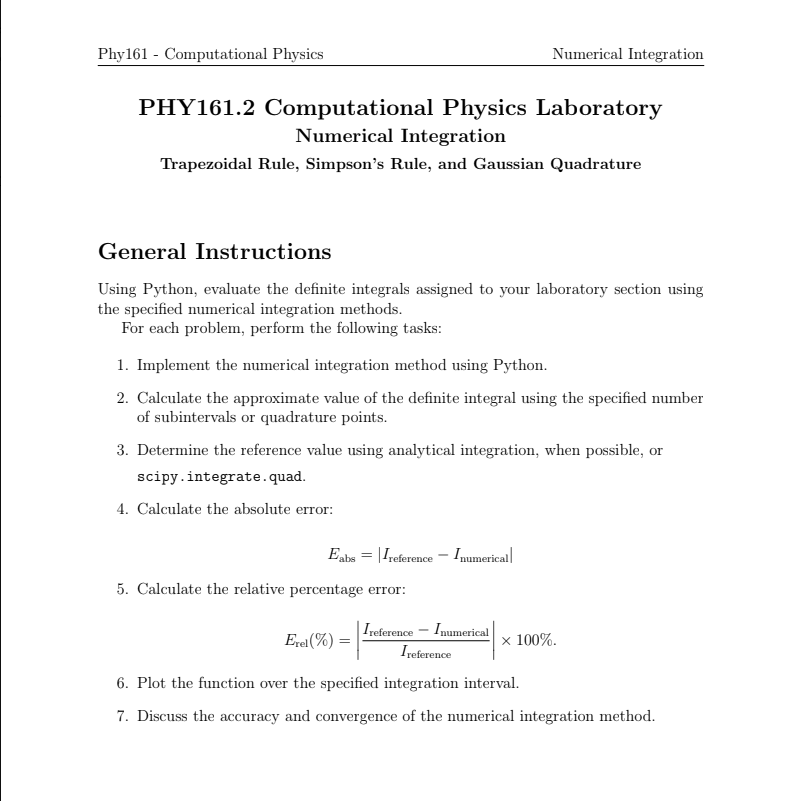

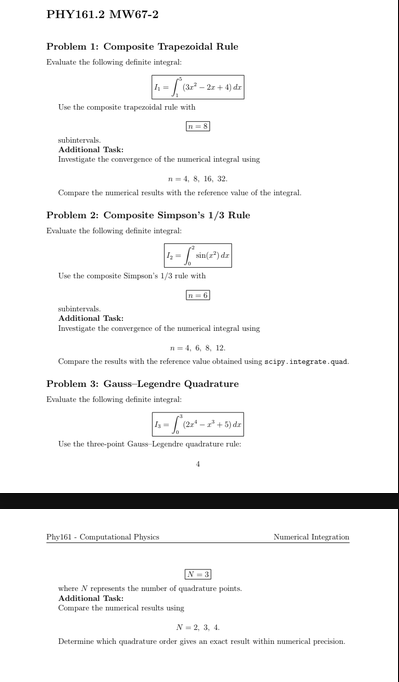

TRAPEZOIDAL RULE
Function: $3x^2 - 2x + 4$
Integration interval: [1, 5]
Reference integral: 116.000000
n         Integral            Relative Error (%)    Absolute Error 
---------------------------------------------------------------------------
4         118.000000          1.724138              2.000000       
8         116.500000          0.431034              0.500000       
16        116.125000          0.107759              0.125000       
32        116.031250          0.026940              0.031250       


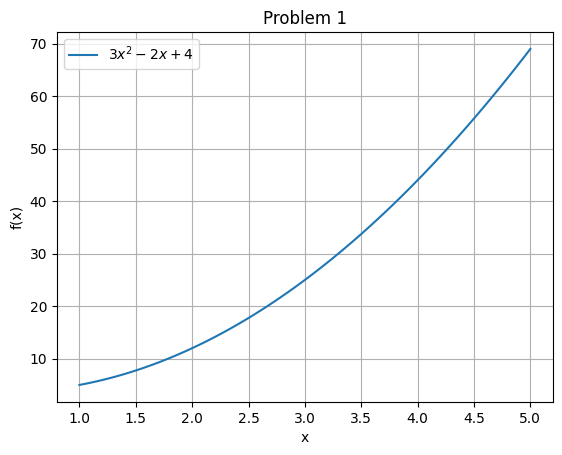

SIMPSON'S 1/3 RULE
Function: $\sin(x^2)$
Integration interval: [0, 2]
Reference integral: 0.804776
n         Integral            Relative Error (%)    Absolute Error 
---------------------------------------------------------------------------
4         0.838008            4.129287              0.033232       
6         0.810356            0.693300              0.005580       
8         0.806337            0.193916              0.001561       
12        0.805056            0.034677              0.000279       


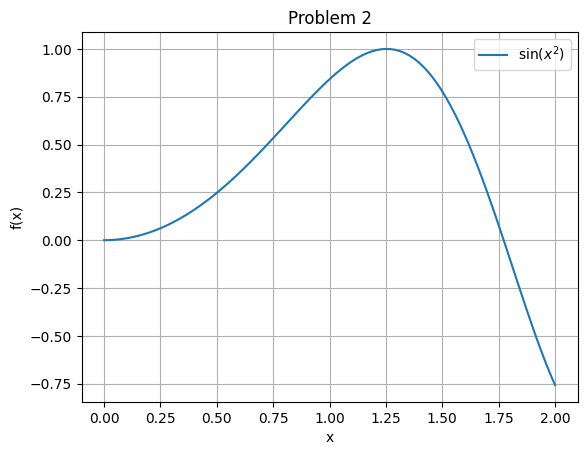

GAUSS-LEGENDRE
Function: $2x^4 - x^3 + 5$
Integration interval: [0, 3]
Reference integral: 91.950000
n         Integral            Relative Error (%)    Absolute Error 
---------------------------------------------------------------------------
2         89.250000           2.936378              2.700000       
3         91.950000           0.000000              0.000000       
4         91.950000           0.000000              0.000000       


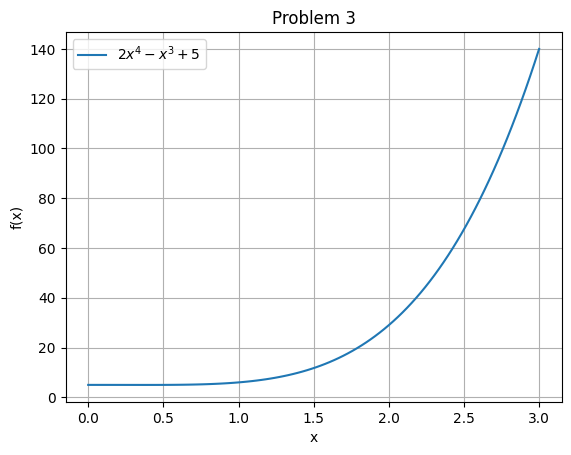

In [68]:

import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate


class Integration:
  def __init__(self, f, a, b, n):
    self.f = f
    self.a = a
    self.b = b
    self.n = n

  def trapezoidal_rule(self):
    if  self.n <= 0:

      raise ValueError("N must be positive!")

    dx = (self.b - self.a) / self.n
    total_area = 0.5 * (self.f(self.a) + self.f(self.b))
    for i in range(1, self.n):
        total_area += self.f(self.a + i * dx)

    return total_area * dx


  def simpson_rule(self):
    if self.n <= 0 or self.n % 2 != 0:
       raise ValueError("N must be a positive even number!")

    dx = (self.b - self.a) / self.n
    total_area = self.f(self.a) + self.f(self.b)
    for i in range(1, self.n):
      x = self.a + i * dx
      if i % 2 == 0:
        total_area += 2 * self.f(x)
      else:
        total_area += 4 * self.f(x)
    return (dx / 3 ) * total_area

  def gauss_legendre(self):
    if self.n <= 0:
      raise ValueError("N must be positive!")

    nodes, weights = np.polynomial.legendre.leggauss(self.n)

    x = (self.b - self.a) / 2 * nodes + (self.b + self.a) / 2

    total_area = 0

    for i in range(self.n):
      total_area += weights[i] * self.f(x[i])
    return (self.b - self.a) / 2 * total_area

  def graph(self, title, label):
    x = np.linspace(self.a, self.b, 100)
    y = self.f(x)
    plt.plot(x, y, label = label)
    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.legend()
    plt.title(title)
    plt.grid(True)
    plt.show()

f1, a, b = lambda x: (3*(x**2)) - (2*x) + 4, 1, 5
f2, c, d = lambda x: np.sin(x**2), 0, 2
f3, g, h = lambda x: (2*(x**4)) - (x**3) + 5, 0, 3
problems = [
    {
        "name": "Trapezoidal Rule",
        "function": f1,
        "a" : a,
        "b" : b,
        "method": "trapezoidal_rule",
        "n_values": [4, 8, 16, 32],
        "title": "Problem 1",
        "label": r"$3x^2 - 2x + 4$"

    },
    {
        "name": "Simpson's 1/3 Rule",
        "function": f2,
        "a": c,
        "b": d,
        "method": "simpson_rule",
        "n_values": [4, 6, 8, 12],
        "title": "Problem 2",
        "label": r"$\sin(x^2)$"
    },
    {
        "name": "Gauss-Legendre",
        "function": f3,
        "a": g,
        "b": h,
        "method": "gauss_legendre",
        "n_values": [2, 3, 4],
        "title": "Problem 3",
        "label": r"$2x^4 - x^3 + 5$"
    }
]


for config in problems:

    function = config["function"]
    lower = config["a"]
    upper = config["b"]
    method_name = config["method"]
    n_values = config["n_values"]

    reference = scipy.integrate.quad(function, lower, upper)[0]

    print("=" * 75)
    print(config["name"].upper())
    print(f"Function: {config['label']}")
    print(f"Integration interval: [{lower}, {upper}]")
    print(f"Reference integral: {reference:.6f}")
    print("=" * 75)

    print(f"{'n':<10}{'Integral':<20}{'Relative Error (%)':<22}{'Absolute Error':<15}")
    print("-" * 75)

    for n in n_values:
        problem = Integration(function, lower, upper, n)

        integration_method = getattr(problem, method_name)
        result = integration_method()

        relative_error = abs((result - reference) / reference) * 100 if reference != 0 else float('nan')
        absolute_error = abs(result - reference)

        print(f"{n:<10}{result:<20.6f}{relative_error:<22.6f}{absolute_error:<15.6f}")

    # Plot the function
    graph_problem = Integration(function, lower, upper, n_values[0])
    graph_problem.graph(config["title"], config["label"])
